# ByteTrack multi-object tracking with OpenVINO™

This tutorial loads the original PyTorch weights for **conversion only**, exports
FP32 OpenVINO IR, then FP16 and NNCF INT8 IR, validates the models, optionally measures
MOT17 val-half MOTA and IDF1 and runs a bundled 30-second video. Tracking stays on the
host, so tracker thresholds and per-sequence overrides are saved separately.
PyTorch is used here only to construct the models for conversion.

#### Table of contents:
- [Install dependencies](#Install-dependencies)
- [Load the model and tracker configuration](#Load-the-model-and-tracker-configuration)
- [Export FP32 and FP16 IR](#Export-FP32-and-FP16-IR)
- [Select device and validate inference](#Select-device-and-validate-inference)
- [Quantize to INT8](#Quantize-to-INT8)
- [Evaluate on MOT17 val-half](#Evaluate-on-MOT17-val-half)
- [Track the first 30 seconds](#Track-the-first-30-seconds)

See [README.md](./README.md) for the model and data protocol. The notebook
fetches the public model sources and checkpoints when absent. [bytetrack_nb_utils.py](./bytetrack_nb_utils.py)
supplies the host-side tracking used by both network precisions.

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/byte-track/byte-track.ipynb" />

## Install dependencies
[back to top ⬆️](#Table-of-contents:)

This cell installs Python dependencies in the current kernel. PyTorch runs conversion on CPU; OpenVINO can run the exported models on GPU.

In [1]:
%pip install -q --extra-index-url https://download.pytorch.org/whl/cpu "torch>=2.5" torchvision "openvino>=2026.3" opencv-python numpy scipy pandas matplotlib "motmetrics>=1.4" lap loguru thop yacs termcolor pyyaml tqdm imageio-ffmpeg requests gdown nncf ipywidgets

Note: you may need to restart the kernel to use updated packages.


## Load the model and tracker configuration
[back to top ⬆️](#Table-of-contents:)

YOLOX-X is the network; BYTETracker, thresholds and sequence overrides are host-side. Source and weights are downloaded on first use; the tracker configuration is included with this tutorial. Run from this notebook's folder.

In [2]:
import copy
import json
import os
import subprocess
import sys
import ipywidgets as widgets
import time
from pathlib import Path

import cv2
import numpy as np
import openvino as ov
import torch
from IPython.display import Image, Markdown, display
import bytetrack_nb_utils as U

sys.path.insert(0, str(U.NB_DIR.parents[1] / 'utils'))
# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("byte-track.ipynb")

PROJECT = U.ROOT
if not U.REPO.is_dir():
    U.REPO.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/FoundationVision/ByteTrack.git", str(U.REPO)], check=True)

core = ov.Core()
OUT = PROJECT / "notebooks" / "openvino_tutorial_2026_3" if PROJECT != U.NB_DIR else U.NB_DIR / "output"
IR_DIR = OUT / "models"
(OUT / "results").mkdir(parents=True, exist_ok=True)
print("Model source:", U.REPO, "| OpenVINO devices:", core.available_devices)
if not U.WEIGHTS.is_file():
    import gdown
    U.WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
    downloaded = gdown.download(id="1P4mY0Yyd3PPTybgZkjMYhFri88nTmJX5",
                                output=str(U.WEIGHTS), quiet=False)
    if not downloaded or not U.WEIGHTS.is_file():
        raise RuntimeError(f"Could not download ByteTrack's official MOT17 checkpoint to {U.WEIGHTS}")
cfg = U.load_config()
from yolox.utils import fuse_model
detector = U.YoloxDecoded(
    fuse_model(U.build_yolox_x(U.WEIGHTS)),
    tuple(cfg["detector"]["input_size_hw"]),
    tuple(cfg["detector"]["strides"]),
).eval()
SHAPE = [1, 3, *cfg["detector"]["input_size_hw"]]
print("Weights:", U.WEIGHTS, "| shape:", SHAPE)
print("Tracker configuration:", json.dumps(cfg["tracker"], indent=2))

Model source: ./model/ByteTrack_repo | OpenVINO devices: ['CPU', 'GPU', 'NPU']


checkpoint keys: ['start_epoch', 'model', 'optimizer'] | tensors: 894


Weights: ./model/weights/bytetrack_x_mot17.pth.tar | shape: [1, 3, 800, 1440]
Tracker configuration: {
  "name": "BYTETracker",
  "track_thresh": 0.6,
  "det_thresh_new_track": "track_thresh + 0.1",
  "low_score_thresh": 0.1,
  "match_thresh_first_assoc": 0.9,
  "match_thresh_second_assoc": 0.5,
  "match_thresh_unconfirmed": 0.7,
  "fuse_score": true,
  "track_buffer": 30,
  "frame_rate": 30,
  "min_box_area": 100,
  "max_aspect_ratio_w_over_h": 1.6,
  "mot20": false,
  "motion_model": "Kalman filter, 8-dim constant-velocity (x, y, a, h, vx, vy, va, vh)",
  "association": "IoU distance + Hungarian (lap.lapjv)",
  "reid": "not used by ByteTrack"
}


## Export FP32 and FP16 IR
[back to top ⬆️](#Table-of-contents:)

Export an uncompressed FP32 IR, then compress its weights to FP16. Store the tracking configuration alongside the IR and in its metadata.

In [3]:
fp32_xml = IR_DIR / "FP32" / "bytetrack_x_mot17.xml"
fp16_xml = IR_DIR / "FP16" / "bytetrack_x_mot17.xml"

def save_ir(model, path, fp16):
    path.parent.mkdir(parents=True, exist_ok=True)
    model.set_rt_info(json.dumps(cfg), ["bytetrack_config"])
    ov.save_model(model, str(path), compress_to_fp16=fp16)
    (path.parent / "bytetrack_config.json").write_text(json.dumps(cfg, indent=2))

if not fp32_xml.exists():
    model = ov.convert_model(
        detector, example_input=torch.zeros(SHAPE), input=[ov.PartialShape(SHAPE)]
    )
    save_ir(model, fp32_xml, fp16=False)
if not fp16_xml.exists():
    save_ir(core.read_model(fp32_xml), fp16_xml, fp16=True)
for xml in (fp32_xml, fp16_xml):
    print(xml, "| config in IR:", core.read_model(xml).has_rt_info(["bytetrack_config"]))

<python-env>/lib/python3.12/site-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
<python-env>/lib/python3.12/site-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


./output/models/FP32/bytetrack_x_mot17.xml | config in IR: True
./output/models/FP16/bytetrack_x_mot17.xml | config in IR: True


## Select device and validate inference
[back to top ⬆️](#Table-of-contents:)

Set `device` to an available OpenVINO device. GPU FP32 explicitly requests `f32`; otherwise the plugin may execute FP32 IR at FP16 precision.

In [4]:
device = widgets.Dropdown(options=core.available_devices,
                          value="GPU" if "GPU" in core.available_devices else "CPU",
                          description="Device:")
print("OpenVINO device:", device.value, "| available:", core.available_devices)
fp32_props = {"INFERENCE_PRECISION_HINT": "f32"} if device.value == "GPU" else {}
runners = {
    "OV_FP32": U.ov_runner(core, str(fp32_xml), device.value, **fp32_props),
    "OV_FP16": U.ov_runner(core, str(fp16_xml), device.value),
}
video = Path("pedestrians_cc0_30s.mp4")
capture = cv2.VideoCapture(str(video))
ok, img = capture.read()
capture.release()
if not ok:
    raise FileNotFoundError(f"Cannot read the bundled video: {video}")
x, _ = U.preprocess(img, cfg)
with torch.inference_mode():
    reference = detector(torch.from_numpy(x)).numpy()
for tag, run in runners.items():
    prediction, ms = U.timeit(run, x, n=5)
    print(tag, f"{ms:.1f} ms", "cosine vs PyTorch FP32:", U.cosine(prediction, reference))

OpenVINO device: GPU | available: ['CPU', 'GPU', 'NPU']


OV_FP32 211.7 ms cosine vs PyTorch FP32: 0.9999999999995398


OV_FP16 29.2 ms cosine vs PyTorch FP32: 0.9999995908071244


## Quantize to INT8
[back to top ⬆️](#Table-of-contents:)

Calibrate the **FP32** detector IR using 32 evenly spaced frames of the bundled clip. NNCF's mixed preset keeps the box-decode tail and final prediction convolutions in floating point. This video-only calibration is a self-contained demonstration, **not** an independent accuracy measurement; use the optional MOT17 section for MOTA/IDF1.

In [5]:
def calibration_frames(path, count=32):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise FileNotFoundError(f"Cannot open calibration video: {path}")
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < count:
        cap.release()
        raise ValueError(f"Need at least {count} video frames for INT8 calibration; got {total}")
    indices = set(np.linspace(0, total - 1, count).round().astype(int))
    frames = []
    for index in range(total):
        ok, frame = cap.read()
        if not ok:
            cap.release()
            raise RuntimeError(f"Could not read calibration frame {index + 1} from {path}")
        if index in indices:
            frames.append(frame)
    cap.release()
    if len(frames) != count:
        raise RuntimeError(f"Expected {count} calibration frames, got {len(frames)}")
    return frames
import nncf

int8_xml = IR_DIR / "INT8" / "bytetrack_x_mot17.xml"
if not int8_xml.exists():
    calibration = [U.preprocess(frame, cfg)[0] for frame in calibration_frames(video)]
    fp32_model = core.read_model(fp32_xml)
    ops = fp32_model.get_ordered_ops()
    last_transpose = max(i for i, op in enumerate(ops) if op.get_type_name() == "Transpose")
    ignored = [
        op.get_friendly_name() for i, op in enumerate(ops)
        if (i >= last_transpose and op.get_type_name() not in ("Constant", "Result"))
        or (op.get_type_name() == "Convolution"
            and any(name in op.get_friendly_name()
                    for name in ("reg_preds", "obj_preds", "cls_preds")))
    ]
    quantized = nncf.quantize(
        fp32_model, nncf.Dataset(calibration),
        subset_size=len(calibration), preset=nncf.QuantizationPreset.MIXED,
        ignored_scope=nncf.IgnoredScope(names=ignored, validate=False),
    )
    save_ir(quantized, int8_xml, fp16=False)
    del calibration, quantized
int8_model = core.read_model(int8_xml)
fq_count = sum(op.get_type_name() == "FakeQuantize" for op in int8_model.get_ordered_ops())
if fq_count == 0:
    raise RuntimeError(f"INT8 IR has no FakeQuantize nodes: {int8_xml}")
runners["OV_INT8"] = U.ov_runner(core, str(int8_xml), device.value)
prediction, ms = U.timeit(runners["OV_INT8"], x, n=5)
print(f"NNCF {nncf.__version__} | INT8 detector: {int8_xml} | "
      f"{fq_count} FakeQuantize nodes | {ms:.1f} ms | "
      f"cosine vs PyTorch FP32: {U.cosine(prediction, reference):.5f}")

INFO:nncf:18 ignored nodes were found by names in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 313 __module.model.head.cls_preds.0/aten::_convolution/Convolution
327 __module.model.head.cls_preds.0/aten::_convolution/Add
341 __module.model.head/aten::sigmoid/Sigmoid_1



INFO:nncf:Not adding activation input quantizer for operation: 314 __module.model.head.obj_preds.0/aten::_convolution/Convolution
328 __module.model.head.obj_preds.0/aten::_convolution/Add
342 __module.model.head/aten::sigmoid/Sigmoid



INFO:nncf:Not adding activation input quantizer for operation: 315 __module.model.head.reg_preds.0/aten::_convolution/Convolution
329 __module.model.head.reg_preds.0/aten::_convolution/Add



INFO:nncf:Not adding activation input quantizer for operation: 437 __module.model.head.cls_preds.1/aten::_convolution/Convolution
446 __module.model.head.cls_preds.1/aten::_convolution/Add
455 __module.model.head/aten::sigmoid/Sigmoid_3



...

INFO:nncf:Not adding activation input quantizer for operation: 398 Multiply_18177
410 aten::mul/Multiply



INFO:nncf:Not adding activation input quantizer for operation: 399 aten::exp/Exp


INFO:nncf:Not adding activation input quantizer for operation: 411 aten::mul/Multiply_1


INFO:nncf:Not adding activation input quantizer for operation: 400 aten::cat/Concat


NNCF 3.4.0 | INT8 detector: ./output/models/INT8/bytetrack_x_mot17.xml | 174 FakeQuantize nodes | 17.8 ms | cosine vs PyTorch FP32: 0.99924


## Evaluate on MOT17 val-half
[back to top ⬆️](#Table-of-contents:)

Optional: the MOT17 FRCNN train sequences are not bundled. Put them in `data/MOT17/train/`, then set `RUN_MOT17_ACCURACY = True` to evaluate all seven second halves with the same tracker configuration. Set `SEQUENCES` to `['MOT17-09-FRCNN']` for a shorter run.

In [6]:
RUN_MOT17_ACCURACY = False
SEQUENCES = None
if RUN_MOT17_ACCURACY:
    if not any(U.MOT17_TRAIN.glob("MOT17-*-FRCNN/img1/*.jpg")):
        raise FileNotFoundError(f"MOT17 FRCNN train sequences required in {U.MOT17_TRAIN}")
    accuracy = {
        tag: U.mot_eval(run, cfg, tag, seqs=SEQUENCES, out_root=str(OUT / "results" / "accuracy"))
        for tag, run in runners.items()
    }
    display(Markdown(
        "| OpenVINO IR | MOTA | IDF1 | IDs | Detector ms/frame |\n"
        "|---|---:|---:|---:|---:|\n" +
        "\n".join(
            f"| {tag} | {m['MOTA']:.2f} | {m['IDF1']:.2f} | {m['IDs']} | {m['detector_ms_per_frame']:.1f} |"
            for tag, m in accuracy.items()
        )
    ))
else:
    print("MOT17 accuracy not run; set RUN_MOT17_ACCURACY=True after providing the FRCNN dataset.")

MOT17 accuracy not run; set RUN_MOT17_ACCURACY=True after providing the FRCNN dataset.


## Track the first 30 seconds
[back to top ⬆️](#Table-of-contents:)

Use the bundled 30-second excerpt of the test video. FP32, FP16 and INT8 run the same host-side tracker. Each run saves a full annotated MP4 and displays a contact sheet.

**OV_FP32**: 900 frames · [Open full tracked video](./output/results/video/OV_FP32_tracked.mp4)

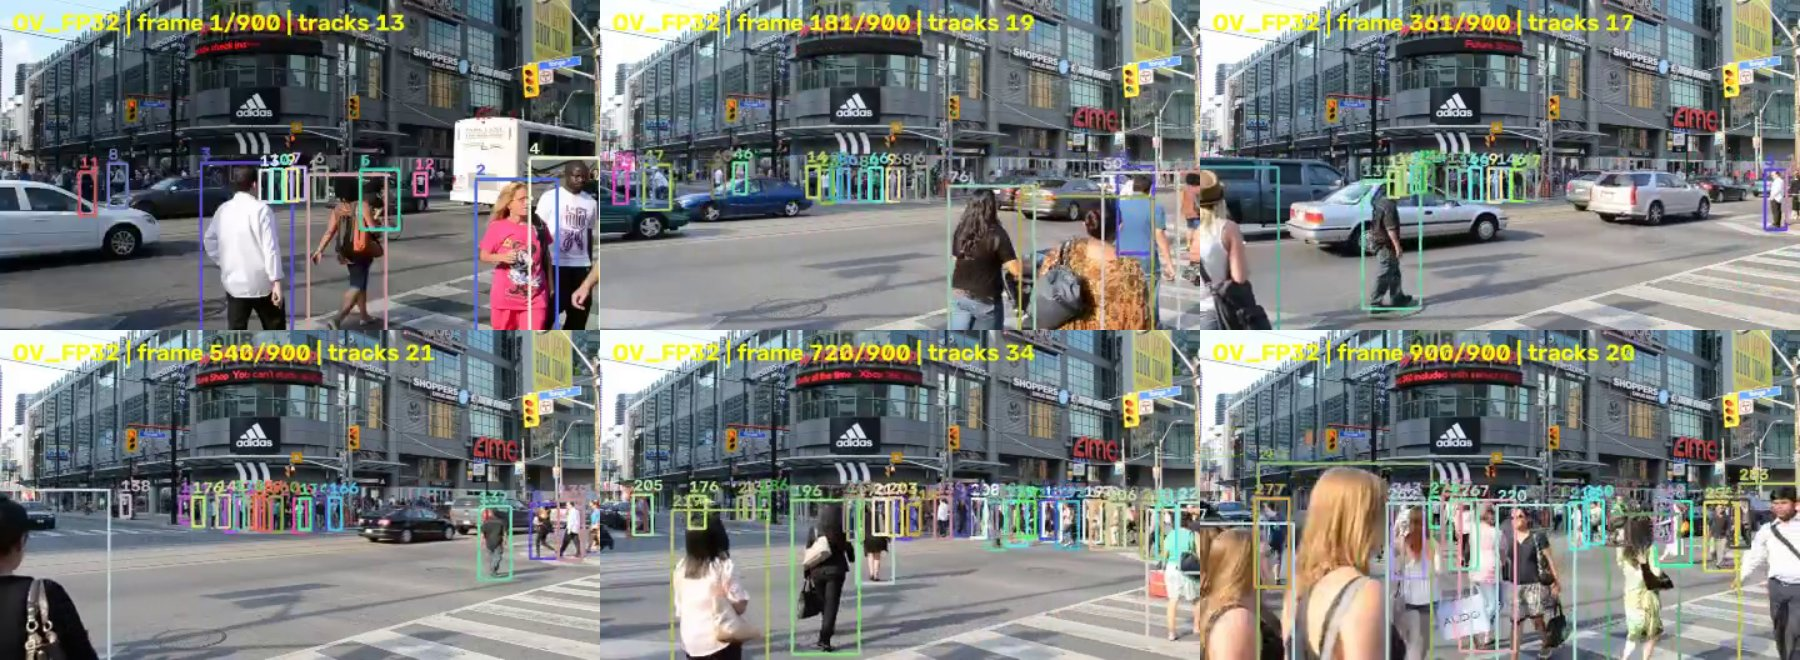

**OV_FP16**: 900 frames · [Open full tracked video](./output/results/video/OV_FP16_tracked.mp4)

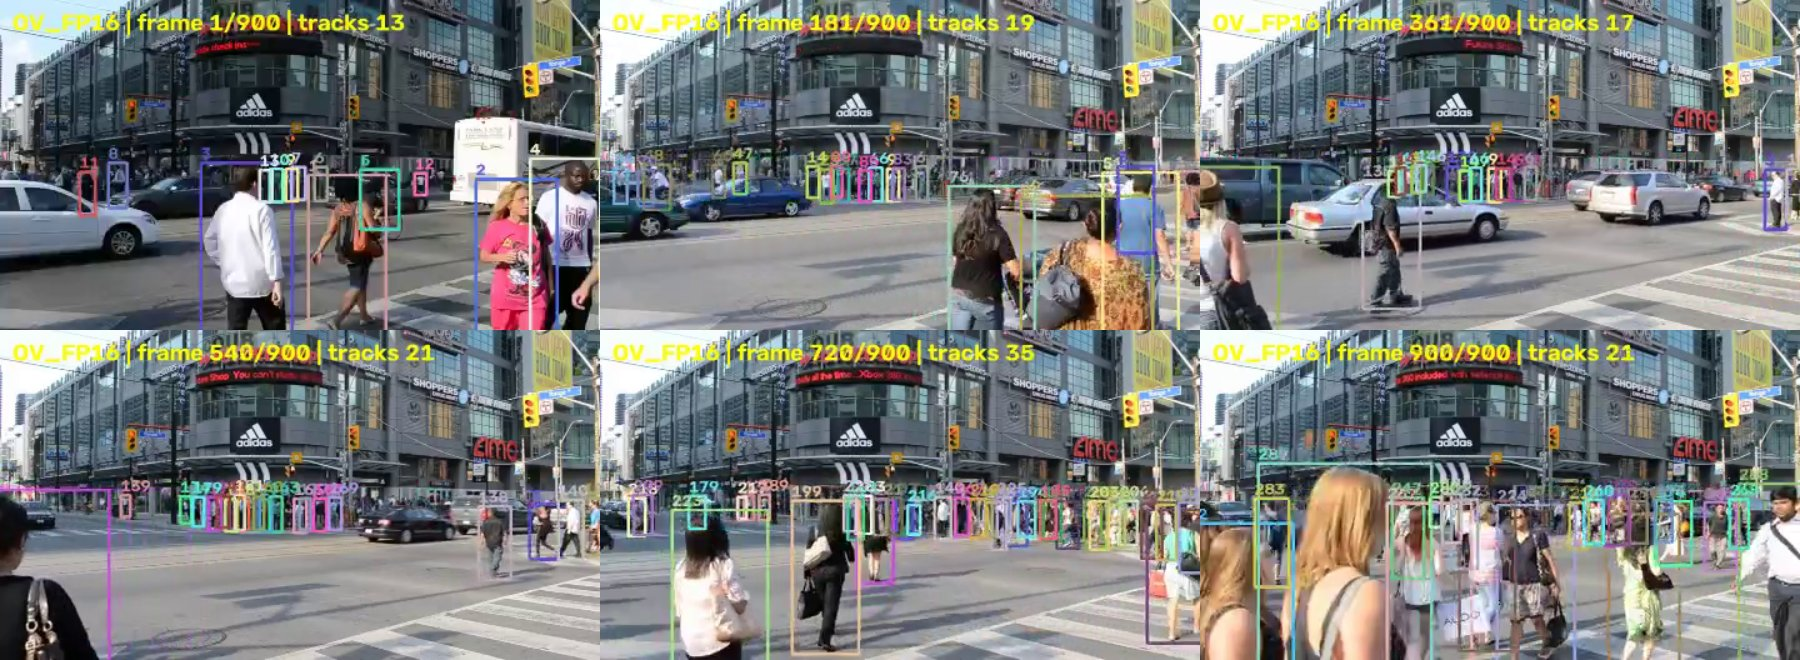

**OV_INT8**: 900 frames · [Open full tracked video](./output/results/video/OV_INT8_tracked.mp4)

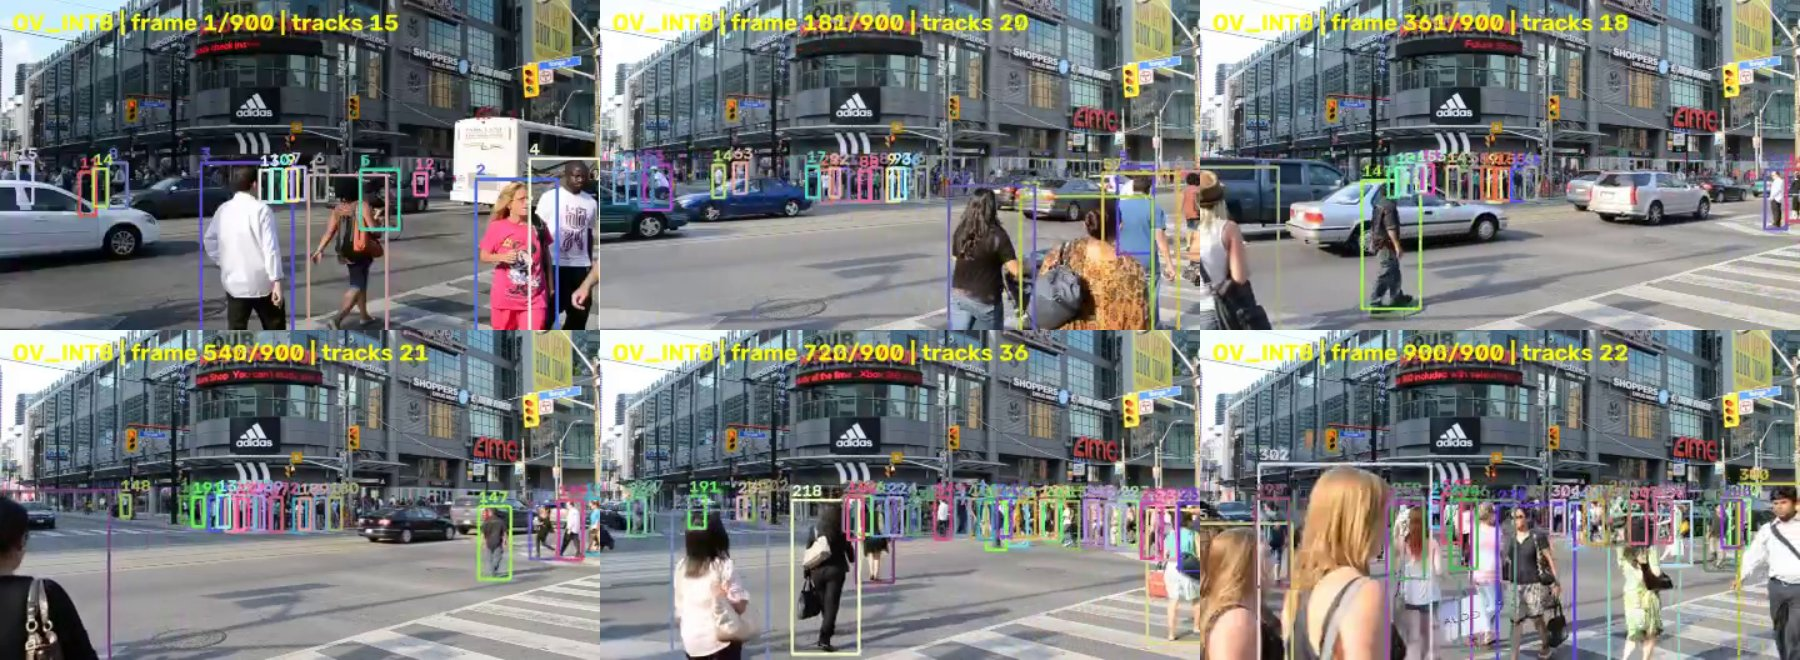

In [7]:
video = Path("pedestrians_cc0_30s.mp4")
cap = cv2.VideoCapture(str(video))
if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {video}")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
if fps <= 0:
    raise ValueError(f"Invalid video frame rate: {fps}")
if total_frames <= 0:
    raise ValueError(f"Cannot read video frame count: {video}")
limit = int(30 * fps)
expected_frames = min(limit, total_frames)
for tag, run in runners.items():
    result = U.track_video(run, cfg, tag, video=video,
                           out_dir=str(OUT / "results" / "video"), max_frames=limit)
    if result["stats"]["frames"] != expected_frames:
        raise RuntimeError(f"{tag} processed {result['stats']['frames']} of {expected_frames} expected frames")
    sheet = U.video_contact_sheet(
        result["stats"]["mp4"], OUT / "results" / "video" / f"{tag}_contact_sheet.jpg"
    )
    if sheet is None:
        raise RuntimeError(f"The {tag} tracked video could not be decoded for the contact sheet")
    display(Markdown(f"**{tag}**: {expected_frames} frames · "
                     f"[Open full tracked video](./{result['stats']['mp4']})"))
    display(Image(filename=sheet, width=960))

### Play the tracked videos

The MP4 players are embedded so the executed notebook still shows all three 30-second clips even when `output/` is not shared.

In [8]:
from pathlib import Path
from IPython.display import Markdown, Video, display

for tag in ("OV_FP32", "OV_FP16", "OV_INT8"):
    mp4 = Path("output/results/video") / f"{tag}_tracked.mp4"
    if not mp4.is_file():
        raise FileNotFoundError(f"Tracked video not found: {mp4}; run the tracking cell first")
    display(Markdown(f"### {tag} — 30-second tracked video"))
    display(Video(filename=str(mp4), embed=True, width=720))

### OV_FP32 — 30-second tracked video

### OV_FP16 — 30-second tracked video

### OV_INT8 — 30-second tracked video